# 4. Analiza spektralna

**Arkadiusz Liber** · *Falki w praktyce. Od wzoru do kodu*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/blob/main/rozdzial-04.ipynb)

Notatnik do książki. Zawiera wszystkie programy z tekstu rozdziału oraz ćwiczenia z rozwiązaniami.

Notatnik działa lokalnie (Jupyter) i w Google Colab. Komórki można uruchamiać po kolei poleceniem *Uruchom wszystko*.

In [1]:
# Uruchom tę komórkę jako pierwszą (lokalnie albo w Google Colab).
import sys, subprocess, importlib.util, os
if importlib.util.find_spec("pywt") is None:      # PyWavelets
    subprocess.check_call([sys.executable, "-m", "pip",
                           "install", "-q", "PyWavelets"])
import numpy as np
import matplotlib.pyplot as plt
import pywt

SZARY, NIEBIESKI, RDZAWY, ZIELONY = "#757575", "#1273E2", "#D93B0B", "#078832"
FIOLET, BURSZTYN = "#9258D5", "#B36000"
plt.rcParams.update({
    "text.color": SZARY, "axes.labelcolor": SZARY, "axes.edgecolor": SZARY,
    "xtick.color": SZARY, "ytick.color": SZARY, "axes.titlecolor": SZARY,
    "font.size": 10, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False})


## Programy z tekstu rozdziału

### Kod 4.1. Współczynniki szeregu Fouriera obliczone numerycznie

In [2]:
import numpy as np

N = 4096
x = -np.pi + 2*np.pi*np.arange(N)/N    # jeden okres
dx = 2*np.pi/N
f = x                                  # funkcja piłokształtna

for k in range(1, 6):
    a_k = np.sum(f*np.cos(k*x))*dx/np.pi     # wzór (4.7)
    b_k = np.sum(f*np.sin(k*x))*dx/np.pi     # wzór (4.8)
    print(k, f"{a_k: .4f}", f"{b_k: .4f}",
          f"{2*(-1)**(k+1)/k: .4f}")         # wzór (4.14)

1  0.0015  2.0000  2.0000
2 -0.0015 -1.0000 -1.0000
3  0.0015  0.6667  0.6667
4 -0.0015 -0.5000 -0.5000
5  0.0015  0.4000  0.4000


### Kod 4.2. Ortonormalność bazy trygonometrycznej

In [3]:
import numpy as np

N = 2048
x = 2*np.pi*np.arange(N)/N
dx = 2*np.pi/N

baza = [np.full(N, 1/np.sqrt(2*np.pi))]
for k in range(1, 5):
    baza.append(np.cos(k*x)/np.sqrt(np.pi))
    baza.append(np.sin(k*x)/np.sqrt(np.pi))
B = np.array(baza)

G = B @ B.T * dx              # macierz Grama, wzór (4.9)
print(np.allclose(G, np.eye(len(B))))

True


### Kod 4.3. Transformata funkcji Gaussa: wynik numeryczny i wzór z tabeli 4.2

In [4]:
import numpy as np

N, L = 4096, 80.0                 # liczba próbek, długość
dx = L/N
x = (np.arange(N) - N//2)*dx
sigma = 1.5
f = np.exp(-x**2/(2*sigma**2))

# przybliżenie całki (4.16) za pomocą FFT
g = dx*np.fft.fftshift(np.fft.fft(np.fft.ifftshift(f)))
omega = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(N, dx))

wzor = sigma*np.sqrt(2*np.pi)*np.exp(-sigma**2*omega**2/2)
print(np.max(np.abs(g - wzor)))          # rzędu 1e-15

# równość Parsevala (4.22)
dw = omega[1] - omega[0]
print(np.sum(f**2)*dx, np.sum(np.abs(g)**2)*dw/(2*np.pi))

8.90927188716351e-16
2.658680776358274 2.658680776358169


### Kod 4.4. Własność przesunięcia i własność splotu

In [5]:
import numpy as np

N = 1024
x = np.arange(N)
f = np.exp(-(x - 300)**2/200.0)

# przesunięcie o 100 próbek: zmienia się tylko faza
F1 = np.fft.fft(f)
F2 = np.fft.fft(np.roll(f, 100))
print(np.allclose(np.abs(F1), np.abs(F2)))
k = np.arange(N)
print(np.allclose(F2, F1*np.exp(-2j*np.pi*k*100/N)))

# splot kołowy liczony z definicji i przez mnożenie widm
h = np.zeros(N); h[:8] = 1/8          # średnia ruchoma
bezposrednio = np.array(
    [np.sum(f*np.roll(h[::-1], n + 1)) for n in range(N)])
przez_widma = np.fft.ifft(F1*np.fft.fft(h)).real
print(np.allclose(bezposrednio, przez_widma))

True
True
True


### Kod 4.5. DFT z definicji i szybka transformata Fouriera

In [6]:
import numpy as np

def dft(f):
    """Dyskretna transformata Fouriera wprost ze wzoru (4.28)."""
    N = len(f)
    n = np.arange(N)
    E = np.exp(-2j*np.pi*np.outer(n, n)/N)
    return E @ f

rng = np.random.default_rng(1)
f = rng.normal(size=256)

F = dft(f)
print(np.allclose(F, np.fft.fft(f)))          # to samo co FFT
print(np.allclose(np.fft.ifft(F).real, f))    # wzór (4.29)
print(np.isclose(np.sum(f**2),
                 np.sum(np.abs(F)**2)/len(f)))  # wzór (4.31)

True
True
True


### Kod 4.6. Aliasing w widmie sygnału próbkowanego zbyt rzadko

In [7]:
import numpy as np

fs, T = 10, 4                  # próbkowanie 10 Hz, 4 sekundy
t = np.arange(0, T, 1/fs)
s = np.sin(2*np.pi*9*t)        # sinusoida 9 Hz

widmo = np.abs(np.fft.rfft(s))
czest = np.fft.rfftfreq(len(s), 1/fs)
print("częstotliwość Nyquista:", fs/2, "Hz")
print("prążek widma przy:", czest[np.argmax(widmo)], "Hz")

częstotliwość Nyquista: 5.0 Hz
prążek widma przy: 1.0 Hz


### Kod 4.7. Przeciek widma i okno Hanna

In [8]:
import numpy as np

fs, N = 100, 200
t = np.arange(N)/fs
s = np.sin(2*np.pi*10.25*t)          # 20,5 okresu w oknie

czest = np.fft.rfftfreq(N, 1/fs)
okna = {"prostokątne": np.ones(N), "Hanna": np.hanning(N)}
for nazwa, okno in okna.items():
    w = np.abs(np.fft.rfft(s*okno))
    w_db = 20*np.log10(w/w.max())
    daleko = np.abs(czest - 10.25) > 5
    print(f"okno {nazwa}: najwyższy prążek dalej niż "
          f"5 Hz od sygnału: {w_db[daleko].max():.0f} dB")

okno prostokątne: najwyższy prążek dalej niż 5 Hz od sygnału: -24 dB
okno Hanna: najwyższy prążek dalej niż 5 Hz od sygnału: -69 dB


### Kod 4.8. Okienkowa transformata Fouriera z krótkim i z długim oknem

In [9]:
import numpy as np
from scipy.signal import stft

fs = 1000
t = np.arange(0, 2, 1/fs)
s = np.sin(2*np.pi*100*t) + np.sin(2*np.pi*115*t)
s[990] += 15                   # dwa impulsy odległe o 30 ms
s[1020] += 15

for dl in (32, 512):           # długość okna w próbkach
    f, tau, S = stft(s, fs, window="hann",
                     nperseg=dl, noverlap=dl - 4)
    print(f"okno {dl/fs*1000:.0f} ms: rozdzielczość "
          f"w częstotliwości {f[1]:.1f} Hz, "
          f"kształt wyniku {S.shape}")

okno 32 ms: rozdzielczość w częstotliwości 31.2 Hz, kształt wyniku (17, 501)
okno 512 ms: rozdzielczość w częstotliwości 2.0 Hz, kształt wyniku (257, 501)


### Kod 4.9. Iloczyn szerokości w czasie i w pulsacji

In [10]:
import numpy as np

def szerokosci(w, x):
    """Zwraca sigma_x i sigma_omega funkcji w(x)."""
    dx = x[1] - x[0]
    p = np.abs(w)**2
    p /= np.sum(p)*dx
    sx = np.sqrt(np.sum(x**2*p)*dx - (np.sum(x*p)*dx)**2)
    W = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(w)))
    om = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(len(x), dx))
    q = np.abs(W)**2
    dw = om[1] - om[0]
    q /= np.sum(q)*dw
    so = np.sqrt(np.sum(om**2*q)*dw - (np.sum(om*q)*dw)**2)
    return sx, so

N, L = 2**14, 200.0
x = (np.arange(N) - N//2)*L/N
okna = {"Gaussa": np.exp(-x**2/2),
        "trójkątne": np.clip(1 - np.abs(x)/2, 0, None),
        "dwustronne wykładnicze": np.exp(-np.abs(x))}
for nazwa, w in okna.items():
    sx, so = szerokosci(w, x)
    print(f"{nazwa}: {sx*so:.3f}")

Gaussa: 0.500
trójkątne: 0.548
dwustronne wykładnicze: 0.710


## Ćwiczenia i rozwiązania

### Ćwiczenie 4.1
Wyznacz współczynniki szeregu Fouriera fali prostokątnej równej 1 dla 0 < x < π i −1 dla −π < x < 0. Porównaj wynik ze wzorem (1.7).

### Rozwiązanie 4.1

In [11]:
N = 4096
x = -np.pi + 2*np.pi*(np.arange(N) + 0.5)/N
dx = 2*np.pi/N
f = np.sign(x)
for k in range(1, 8):
    a_k = np.sum(f*np.cos(k*x))*dx/np.pi
    b_k = np.sum(f*np.sin(k*x))*dx/np.pi
    wzor = 4/(np.pi*k) if k % 2 else 0.0
    print(k, f"a_k = {a_k: .4f}", f"b_k = {b_k: .4f}", f"wzór: {wzor: .4f}")

1 a_k =  0.0000 b_k =  1.2732 wzór:  1.2732
2 a_k =  0.0000 b_k =  0.0000 wzór:  0.0000
3 a_k = -0.0000 b_k =  0.4244 wzór:  0.4244
4 a_k =  0.0000 b_k = -0.0000 wzór:  0.0000
5 a_k = -0.0000 b_k =  0.2546 wzór:  0.2546
6 a_k =  0.0000 b_k = -0.0000 wzór:  0.0000
7 a_k =  0.0000 b_k =  0.1819 wzór:  0.1819


### Ćwiczenie 4.2
Sprawdź numerycznie równość Parsevala dla funkcji piłokształtnej z przykładu 4.1: średnia wartość kwadratu funkcji na okresie jest równa połowie sumy kwadratów współczynników b_k.

### Rozwiązanie 4.2

In [12]:
srednia_kwadratu = np.pi**2/3                 # (1/2π) ∫ x² dx na (−π, π)
for K in (10, 100, 1000, 100000):
    k = np.arange(1, K + 1)
    print(K, 0.5*np.sum((2/k)**2), srednia_kwadratu)

10 3.0995354623330815 3.289868133696453
100 3.2699678003697863 3.289868133696453
1000 3.2878691333631203 3.289868133696453
100000 3.289848133796453 3.289868133696453


### Ćwiczenie 4.3
Korzystając z kodu 4.3, wyznacz numerycznie transformatę funkcji exp(−|x|) i porównaj ją z tabelą 4.2.

### Rozwiązanie 4.3

największa różnica dla |ω| < 20: 1.552492650387649e-06


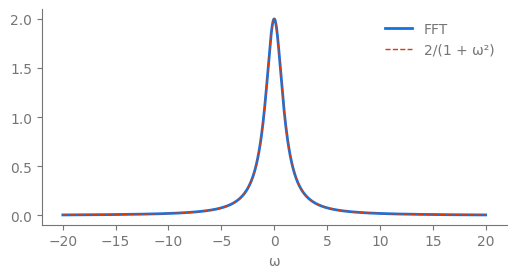

In [13]:
N, L = 2**16, 200.0
dx = L/N
x = (np.arange(N) - N//2)*dx
f = np.exp(-np.abs(x))
g = dx*np.fft.fftshift(np.fft.fft(np.fft.ifftshift(f))).real
omega = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(N, dx))
wzor = 2/(1 + omega**2)
zakres = np.abs(omega) < 20
print("największa różnica dla |ω| < 20:", np.max(np.abs(g - wzor)[zakres]))
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(omega[zakres], g[zakres], color=NIEBIESKI, lw=2, label="FFT")
ax.plot(omega[zakres], wzor[zakres], color=RDZAWY, lw=1, ls="--",
        label="2/(1 + ω²)")
ax.set_xlabel("ω"); ax.legend(frameon=False)
plt.show()

### Ćwiczenie 4.4
Pokaż numerycznie własność skalowania: porównaj widma amplitudowe funkcji Gaussa o σ = 1 i σ = 0,5.

### Rozwiązanie 4.4

σ = 1.0: szerokość widma = 0.7071 (teoria: 0.7071)
σ = 0.5: szerokość widma = 1.4142 (teoria: 1.4142)


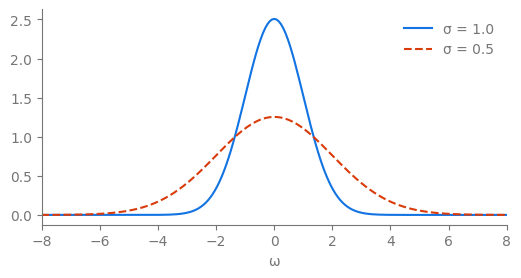

In [14]:
N, L = 4096, 80.0
dx = L/N
x = (np.arange(N) - N//2)*dx
omega = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(N, dx))
dw = omega[1] - omega[0]
fig, ax = plt.subplots(figsize=(6, 2.8))
for sigma, kol, ls in ((1.0, NIEBIESKI, "-"), (0.5, RDZAWY, "--")):
    f = np.exp(-x**2/(2*sigma**2))
    g = np.abs(dx*np.fft.fftshift(np.fft.fft(np.fft.ifftshift(f))))
    p = g**2/np.sum(g**2)
    print(f"σ = {sigma}: szerokość widma = {np.sqrt(np.sum(omega**2*p)):.4f}",
          f"(teoria: {1/(np.sqrt(2)*sigma):.4f})")
    ax.plot(omega, g, color=kol, ls=ls, label=f"σ = {sigma}")
ax.set_xlim(-8, 8); ax.set_xlabel("ω"); ax.legend(frameon=False)
plt.show()

### Ćwiczenie 4.5
Sygnał jest sumą sinusoid o częstotliwościach 50 Hz i 120 Hz. Wyznacz jego widmo przy próbkowaniu 1000 Hz i 200 Hz. Pod jaką częstotliwością pojawi się w drugim przypadku składowa 120 Hz?

### Rozwiązanie 4.5

In [15]:
for fs in (1000, 200):
    t = np.arange(0, 1, 1/fs)
    s = np.sin(2*np.pi*50*t) + np.sin(2*np.pi*120*t)
    w = np.abs(np.fft.rfft(s))
    czest = np.fft.rfftfreq(len(s), 1/fs)
    prazki = np.sort(czest[np.argsort(w)[-2:]])
    print(f"próbkowanie {fs} Hz: prążki przy {prazki} Hz")

próbkowanie 1000 Hz: prążki przy [ 50. 120.] Hz
próbkowanie 200 Hz: prążki przy [50. 80.] Hz


### Ćwiczenie 4.6
Ile próbek sygnału próbkowanego z częstotliwością 1000 Hz potrzeba, aby rozróżnić w widmie składowe 100 Hz i 101 Hz?

### Rozwiązanie 4.6

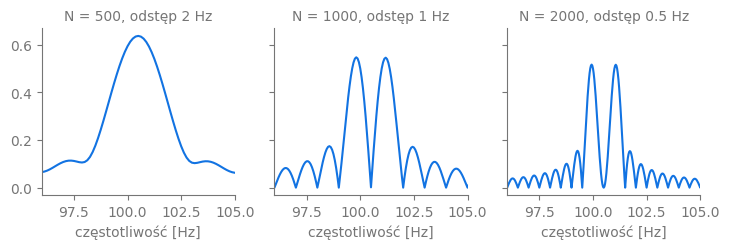

In [16]:
fs = 1000
fig, axs = plt.subplots(1, 3, figsize=(7.4, 2.6), sharey=True)
for ax, N in zip(axs, (500, 1000, 2000)):
    t = np.arange(N)/fs
    s = np.sin(2*np.pi*100*t) + np.sin(2*np.pi*101*t)
    w = np.abs(np.fft.rfft(s, 16*N))/N        # zagęszczenie osi częstotliwości
    czest = np.fft.rfftfreq(16*N, 1/fs)
    ax.plot(czest, w, color=NIEBIESKI)
    ax.set_xlim(96, 105); ax.set_title(f"N = {N}, odstęp {fs/N:g} Hz")
    ax.set_xlabel("częstotliwość [Hz]")
plt.tight_layout(); plt.show()

### Ćwiczenie 4.7
W kodzie 4.7 zamień okno Hanna na okno Hamminga (`np.hamming`) i Blackmana (`np.blackman`). Porównaj poziom przecieku.

### Rozwiązanie 4.7

In [17]:
fs, N = 100, 200
t = np.arange(N)/fs
s = np.sin(2*np.pi*10.25*t)
czest = np.fft.rfftfreq(N, 1/fs)
daleko = np.abs(czest - 10.25) > 5
okna = {"prostokątne": np.ones(N), "Hanna": np.hanning(N),
        "Hamminga": np.hamming(N), "Blackmana": np.blackman(N)}
for nazwa, okno in okna.items():
    w = np.abs(np.fft.rfft(s*okno))
    w_db = 20*np.log10(w/w.max())
    szer = np.sum(w_db > -6)*fs/N               # szerokość prążka głównego
    print(f"{nazwa:12s} przeciek: {w_db[daleko].max():6.0f} dB, "
          f"szerokość prążka (−6 dB): {szer:.1f} Hz")

prostokątne  przeciek:    -24 dB, szerokość prążka (−6 dB): 1.0 Hz
Hanna        przeciek:    -69 dB, szerokość prążka (−6 dB): 1.0 Hz
Hamminga     przeciek:    -43 dB, szerokość prążka (−6 dB): 1.0 Hz
Blackmana    przeciek:    -78 dB, szerokość prążka (−6 dB): 1.0 Hz


### Ćwiczenie 4.8
Wygeneruj sygnał o częstotliwości rosnącej liniowo od 10 Hz do 200 Hz w ciągu 2 sekund i narysuj jego spektrogram dla trzech długości okna. Która długość daje najostrzejszy obraz?

### Rozwiązanie 4.8

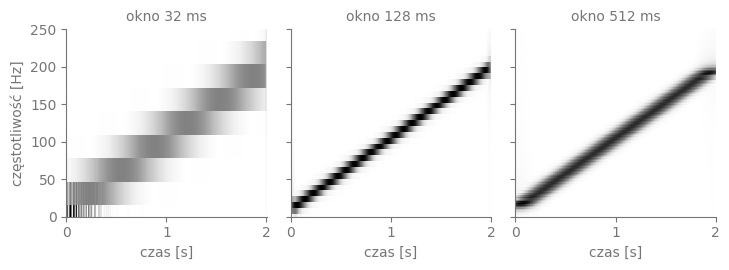

optymalna długość okna rzędu: 103 ms


In [18]:
from scipy.signal import stft, chirp
fs = 1000
t = np.arange(0, 2, 1/fs)
s = chirp(t, f0=10, t1=2, f1=200)
fig, axs = plt.subplots(1, 3, figsize=(7.4, 2.8), sharey=True)
for ax, dl in zip(axs, (32, 128, 512)):
    f, tau, S = stft(s, fs, window="hann", nperseg=dl, noverlap=dl - 4)
    ax.pcolormesh(tau, f, np.abs(S), cmap="Greys", shading="auto")
    ax.set_ylim(0, 250); ax.set_title(f"okno {dl} ms")
    ax.set_xlabel("czas [s]")
axs[0].set_ylabel("częstotliwość [Hz]")
plt.tight_layout(); plt.show()
# Częstotliwość zmienia się z szybkością 95 Hz/s. Najostrzejszy obraz daje okno,
# w którym rozmycie w czasie i w częstotliwości są zrównoważone: około 100 ms.
print("optymalna długość okna rzędu:", round(1000/np.sqrt(95)), "ms")